In [1]:
import pandas as pd
pd.set_option('display.float_format',lambda x:f"{x:.4f}")
df=pd.read_csv('weather/Rainfall.csv')
print(df.shape)
df.tail()

(366, 12)


,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
361,27,1022.7000,18.8000,17.7000,16.9000,15.0000,84,90,yes,0.0000,30.0000,18.4000
362,28,1026.6000,18.6000,17.3000,16.3000,12.8000,75,85,yes,1.0000,20.0000,25.9000
363,29,1025.9000,18.9000,17.7000,16.4000,13.3000,75,78,yes,4.6000,70.0000,33.4000
364,30,1025.3000,19.2000,17.3000,15.2000,13.3000,78,86,yes,1.2000,20.0000,20.9000
365,31,1026.4000,20.5000,17.8000,15.5000,13.0000,74,66,no,5.7000,20.0000,23.3000


In [2]:
df['rainfall'].value_counts()

rainfall
yes    249
no     117
Name: count, dtype: int64

In [3]:
df=df.rename(str.strip,axis=1)
df=df.drop('day',axis=1)
df=df.dropna(axis=0)
df.info()

<class 'pandas.DataFrame'>
Index: 365 entries, 0 to 365
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pressure       365 non-null    float64
 1   maxtemp        365 non-null    float64
 2   temparature    365 non-null    float64
 3   mintemp        365 non-null    float64
 4   dewpoint       365 non-null    float64
 5   humidity       365 non-null    int64  
 6   cloud          365 non-null    int64  
 7   rainfall       365 non-null    str    
 8   sunshine       365 non-null    float64
 9   winddirection  365 non-null    float64
 10  windspeed      365 non-null    float64
dtypes: float64(8), int64(2), str(1)
memory usage: 34.2 KB


In [4]:
# normal distribution test -> select t test/ u test
import scipy.stats as stats
num_features=[c for c in df.select_dtypes("number").columns]
# only choose number column, omit rainfall column since it is not available for skew and stats.pvalue
print(num_features)
rows=[]
for col in num_features:
    a=df[df['rainfall']=='yes'][col]
    b=df[df['rainfall']=='no'][col]
    rows.append({
        'feature':col,
        'skew_yes':a.skew(),
        'skew_no':b.skew(),
        'shapiro_p_yes':stats.shapiro(a).pvalue,
        'shapiro_p_no':stats.shapiro(b).pvalue,
        'levene_p':stats.levene(a,b).pvalue,
    })
assump=pd.DataFrame(rows).set_index('feature')
assump['normal_in_both_groups']=(assump.shapiro_p_yes>0.05)&(assump.shapiro_p_no>0.05)
print(assump.to_string())
#  Skewness (skew): <-1 negative skew, -1 to 1 normal distribution, >1 positive skew
# Measures the asymmetry of the data distribution. A value close to 0 means the data is perfectly symmetrical (like a normal distribution).Is the left side of the distribution a mirror image of the right side? It does not evaluate the overall structure, the thickness of the tails, or whether the peak is too flat or too pointy.
#  
# Shapiro-Wilk Test (shapiro): >significance --> shape is close enough to standard distribution
# Tests the null hypothesis that the data is normally distributed. It extracts the .pvalue for both groups. Shapiro test tells you a distribution is perfectly normal (\(p > 0.05\))
#  
# Levene's Test (levene): Tests the null hypothesis that both groups have equal variances. It extracts the .pvalue.


['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint', 'humidity', 'cloud', 'sunshine', 'winddirection', 'windspeed']
               skew_yes  skew_no  shapiro_p_yes  shapiro_p_no  levene_p  normal_in_both_groups
feature                                                                                       
pressure         0.3438   0.2319         0.0023        0.0175    0.0872                  False
maxtemp         -0.5698  -0.4976         0.0000        0.0000    0.4282                  False
temparature     -0.7011  -0.5364         0.0000        0.0000    0.1440                  False
mintemp         -0.7794  -0.6118         0.0000        0.0000    0.0645                  False
dewpoint        -0.9795  -0.9397         0.0000        0.0000    0.0122                  False
humidity        -0.4007  -1.3020         0.0017        0.0000    0.1930                  False
cloud           -1.3704  -0.0425         0.0000        0.0022    0.0000                  False
sunshine         0.8

Text(0.5, 1.0, 'Q-Q plot: temparature with rain')

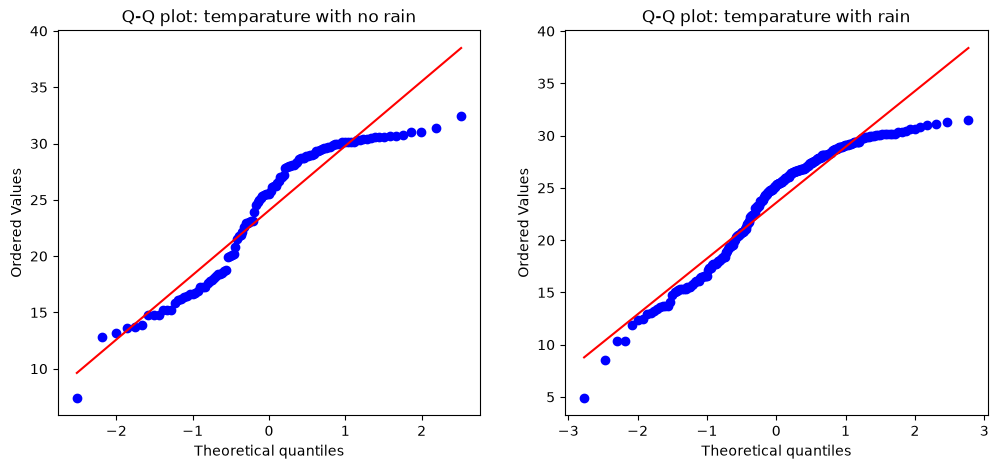

In [5]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,5))
stats.probplot(df[df['rainfall']=='no']['temparature'],dist='norm',plot=axes[0])
axes[0].set_title("Q-Q plot: temparature with no rain")

stats.probplot(df[df['rainfall']=='yes']['temparature'],dist='norm',plot=axes[1])
axes[1].set_title('Q-Q plot: temparature with rain')
#  If dots track tightly along the line: The feature behaves normally. You can confidently trust standard parametric metrics like a t-test.
#  If dots break away at the extreme left (bottom) or extreme right (top): This indicates that your data has "heavy tails" or severe outliers.
#  If the dots form a distinct curve or 'S-shape' off the line: Your data is explicitly skewed. If the curve sits entirely above or below parts of the line, it means your distribution is leaning left or right, prompting you to pivot to a non-parametric test.

In [6]:
# not normal distributed--> choose Mann-Whitney U test, but list t-test as well to learn
rows=[]
for col in num_features:
    a=df[df['rainfall']=='yes'][col]
    b=df[df['rainfall']=='no'][col]
    t,p_t=stats.ttest_ind(a,b,equal_var=False) #welch t-test
    # assume two group does not have equal variances--> safer 
    u,p_u=stats.mannwhitneyu(a,b,alternative='two-sided') #U test
    rows.append({
        'feature':col,
        'mean_yes':a.mean(),
        'mean_no':b.mean(),
        'median_yes':a.median(),
        'median_no':b.median(),
        't_stat':t,
        't_p':p_t,
        'u_stat':u,
        'u_p':p_u,
    })
tests=pd.DataFrame(rows).set_index('feature')
#  Testing many hypotheses at once increases the chance of finding a fake positive result (Type I error) by pure chance.--->bonferroni correction
# a.Adjust the alpha level: Divide your standard significance threshold (α, usually 0.05) by the total number of tests (m). Your new cutoff is α / m.
# b.Adjust the p-value: Multiply each individual p-value by the total number of tests (m) and compare it to your original α.
m=len(tests)
tests['t_p_bonf']=(tests['t_p']*m).clip(upper=1)
tests['u_p_bonf']=(tests['u_p']*m).clip(upper=1)
alpha=0.05
tests['related_t_test']=tests['t_p_bonf']<alpha
tests['related_u_test']=tests['u_p_bonf']<alpha
tests

,mean_yes,mean_no,median_yes,median_no,t_stat,t_p,u_stat,u_p,t_p_bonf,u_p_bonf,related_t_test,related_u_test
feature,,,,,,,,,,,,
pressure,1013.3815,1014.5769,1012.7500,1013.1000,-1.5955,0.1121,13030.0000,0.1163,1.0000,1.0000,False,False
maxtemp,25.7540,27.0709,27.5500,29.1000,-1.9530,0.0521,12271.0000,0.0174,0.5208,0.1743,False,False
temparature,23.5847,24.0538,25.3500,25.5000,-0.7215,0.4714,13273.5000,0.1896,1.0000,1.0000,False,False
mintemp,21.8460,21.9573,23.7000,23.7000,-0.1695,0.8656,13651.0000,0.3626,1.0000,1.0000,False,False
dewpoint,20.5427,18.7667,22.3000,20.9000,2.4444,0.0154,16583.0000,0.0274,0.1544,0.2743,False,False
humidity,83.5403,73.0000,84.0000,75.0000,9.5750,0.0000,23492.5000,0.0000,0.0000,0.0000,True,True
cloud,80.4718,51.2564,84.0000,49.0000,12.6979,0.0000,24907.0000,0.0000,0.0000,0.0000,True,True
sunshine,2.9169,7.5863,1.5000,8.8000,-12.4278,0.0000,4667.5000,0.0000,0.0000,0.0000,True,True
winddirection,100.7661,103.0769,70.0000,70.0000,-0.2420,0.8090,14792.5000,0.7620,1.0000,1.0000,False,False


In [7]:
print('related to rainfall')
print(tests.index[tests['related_u_test']].tolist())
print('not significantly related to rainfall')
print(tests.index[~tests['related_u_test']].tolist())

related to rainfall
['humidity', 'cloud', 'sunshine', 'windspeed']
not significantly related to rainfall
['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint', 'winddirection']


In [8]:
# effect size/ correlation metrics
# Eta-squared(η²), measures the strength of the relationship between a categorical variable (with two or more groups) and a continuous numerical variable.
# η² = (variance between groups) / (total variance) 
# η² range from 0 to 1, 0 indicate no relation, 1 means strong relation
# η² only capture the magnitude of the difference, does not capture the direction of relation, since category cannot have negative slope.
#  0.01: Small effect
#  0.06: Medium effect
#  0.14 or higher: Large effect (so 0.5 is massive!)


In [9]:
import numpy as np
def correlation_ratio(categories,values):
    # categories are rainfall column with yes/no
    # values are other columns with numbers
    categories=np.asarray(categories)
    values=np.asarray(values,dtype=float)
    grand_mean=values.mean()
    ss_between = sum(
        (categories == c).sum() * (values[categories == c].mean() - grand_mean) ** 2
        for c in np.unique(categories)
    )
    ss_total=((values-grand_mean)**2).sum()
    return np.sqrt(ss_between/ss_total)
# categories=np.asarray(df['rainfall'])
# for c,n in np.unique(categories,return_counts=True):
#     print(c,n)
# ---> get: no yes
#           117 248
y_bin=(df['rainfall']=="yes").astype(int)
rows=[]
for col in num_features:
    eta=correlation_ratio(df['rainfall'],df[col])
    r_pb,p_pb=stats.pointbiserialr(y_bin,df[col])
    # r_pb: correlation coefficient, how strongly two variables are related and which direction, range from -1 to 1
    # p_pb:p value 
    rows.append({
        "feature":col,
        "eta":eta,
        "eta_squared":eta**2,
        "point_biserial_r":r_pb,
        "pont_biserial_pb":p_pb,
    })
    
effects=pd.DataFrame(rows).set_index('feature')
# print(effects)
# for col in num_features:
#     e_val=effects.loc[col,'eta']
#     r_val=effects.loc[col,'point_biserial_r']
#     print(f"{col}:eta={e_val:.6f},|r_pb|={abs(r_val):.6f},diff={e_val-abs(r_val)}")

assert np.allclose(effects["eta"], effects["point_biserial_r"].abs()), "eta != |r_pb|"
# condition true-> keep running, condition false-> raise an AssertionError(as a switch to let the code pass/stop)
# condition: np.allclose--> sanity check eta and point_biserial should be euqal within tolerance
# "eta != |r_pb|" error message, eta and pb equal in two groups in one-way anova 

def strength(eta2):
    return('negligible' if eta2<0.01 else 'small' if eta2<0.06 else 'medium' if eta2<0.14 else 'large')
effects['strength']=effects['eta_squared'].map(strength)
effects.sort_values('eta',ascending=False)


,eta,eta_squared,point_biserial_r,pont_biserial_pb,strength
feature,,,,,
cloud,0.6256,0.3914,0.6256,0.0000,large
sunshine,0.5541,0.3070,-0.5541,0.0000,large
humidity,0.4891,0.2392,0.4891,0.0000,large
windspeed,0.1545,0.0239,0.1545,0.0031,small
dewpoint,0.1384,0.0192,0.1384,0.0081,small
maxtemp,0.1029,0.0106,-0.1029,0.0494,small
pressure,0.0872,0.0076,-0.0872,0.0964,negligible
temparature,0.0389,0.0015,-0.0389,0.4587,negligible
winddirection,0.0132,0.0002,-0.0132,0.8014,negligible


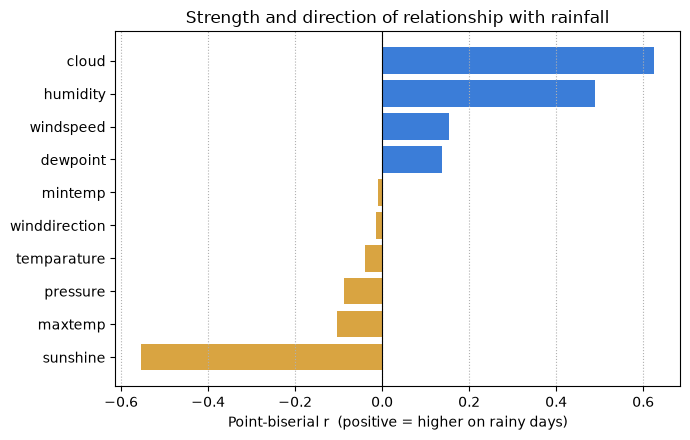

In [10]:
plot_df = effects.sort_values("point_biserial_r")
colors = ["#3b7dd8" if r > 0 else "#d9a441" for r in plot_df["point_biserial_r"]]
_, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(plot_df.index, plot_df["point_biserial_r"], color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Point-biserial r  (positive = higher on rainy days)")
ax.set_title("Strength and direction of relationship with rainfall")
plt.tight_layout()
plt.grid(axis='x',linestyle=':')

In [11]:
# 3 group case
df=pd.read_csv('weather/Rainfall.csv')
df['month']=(df['day'].diff()<0).cumsum()+1
print(df['month'].value_counts().sort_index())
df=df.dropna(axis=0)
df=df.drop('day',axis=1)
df.columns=df.columns.str.strip()


month
1     31
2     29
3     31
4     30
5     31
6     30
7     31
8     31
9     30
10    31
11    30
12    31
Name: count, dtype: int64


In [12]:
rows=[]
for col in num_features:
    F,p_F=stats.f_oneway(df['month'],df[col])
    H,p_H=stats.kruskal(df['month'],df[col])
    rows.append({
        'feature':col,
        'F':F,
        'anova_p':p_F,
        'H':H,
        'kruskal_p':p_H,
        'eta':correlation_ratio(df['month'],df[col])
    })
by_month=pd.DataFrame(rows).set_index('feature')
by_month

,F,anova_p,H,kruskal_p,eta
feature,,,,,
pressure,6979113.1453,0.0000,547.2306,0.0000,0.8650
maxtemp,2956.0286,0.0000,542.2153,0.0000,0.9167
temparature,2474.6371,0.0000,536.2480,0.0000,0.9291
mintemp,1990.7041,0.0000,518.7020,0.0000,0.9177
dewpoint,1378.7888,0.0000,454.9203,0.0000,0.8654
humidity,17455.4883,0.0000,547.3280,0.0000,0.3937
cloud,3118.8387,0.0000,534.6904,0.0000,0.3480
sunshine,58.6394,0.0000,59.7302,0.0000,0.4586
winddirection,492.2555,0.0000,529.0270,0.0000,0.7036


In [13]:
m=len(by_month)
print(m)
by_month["anova_p_bonf"]   = (by_month["anova_p"]   * m).clip(upper=1)
by_month["kruskal_p_bonf"] = (by_month["kruskal_p"] * m).clip(upper=1)
by_month["eta_squared"] = by_month["eta"] ** 2
by_month["strength"] = by_month["eta_squared"].map(strength)
by_month

10


,F,anova_p,H,kruskal_p,eta,anova_p_bonf,kruskal_p_bonf,eta_squared,strength
feature,,,,,,,,,
pressure,6979113.1453,0.0000,547.2306,0.0000,0.8650,0.0000,0.0000,0.7482,large
maxtemp,2956.0286,0.0000,542.2153,0.0000,0.9167,0.0000,0.0000,0.8403,large
temparature,2474.6371,0.0000,536.2480,0.0000,0.9291,0.0000,0.0000,0.8632,large
mintemp,1990.7041,0.0000,518.7020,0.0000,0.9177,0.0000,0.0000,0.8423,large
dewpoint,1378.7888,0.0000,454.9203,0.0000,0.8654,0.0000,0.0000,0.7489,large
humidity,17455.4883,0.0000,547.3280,0.0000,0.3937,0.0000,0.0000,0.1550,large
cloud,3118.8387,0.0000,534.6904,0.0000,0.3480,0.0000,0.0000,0.1211,medium
sunshine,58.6394,0.0000,59.7302,0.0000,0.4586,0.0000,0.0000,0.2103,large
winddirection,492.2555,0.0000,529.0270,0.0000,0.7036,0.0000,0.0000,0.4950,large


In [14]:
out=by_month.sort_values('eta',ascending=False)
for c in ["anova_p", "kruskal_p", "anova_p_bonf", "kruskal_p_bonf"]:
    out[c]=out[c].map("{:.2e}".format)
    # .2e -> format to scientific notation 
out

,F,anova_p,H,kruskal_p,eta,anova_p_bonf,kruskal_p_bonf,eta_squared,strength
feature,,,,,,,,,
temparature,2474.6371,2.18e-236,536.2480,1.24e-118,0.9291,2.18e-235,1.24e-117,0.8632,large
mintemp,1990.7041,1.76e-210,518.7020,8.11e-115,0.9177,1.76e-209,8.11e-114,0.8423,large
maxtemp,2956.0286,1.56e-258,542.2153,6.22e-120,0.9167,1.56e-257,6.22e-119,0.8403,large
dewpoint,1378.7888,3.80e-170,454.9203,6.13e-101,0.8654,3.80e-169,6.13e-100,0.7489,large
pressure,6979113.1453,0.00e+00,547.2306,5.04e-121,0.8650,0.00e+00,5.04e-120,0.7482,large
winddirection,492.2555,1.03e-83,529.0270,4.60e-117,0.7036,1.03e-82,4.60e-116,0.4950,large
sunshine,58.6394,6.04e-14,59.7302,1.09e-14,0.4586,6.04e-13,1.09e-13,0.2103,large
windspeed,726.4856,1.62e-111,447.6670,2.32e-99,0.4471,1.62e-110,2.32e-98,0.1999,large
humidity,17455.4883,0.00e+00,547.3280,4.80e-121,0.3937,0.00e+00,4.80e-120,0.1550,large


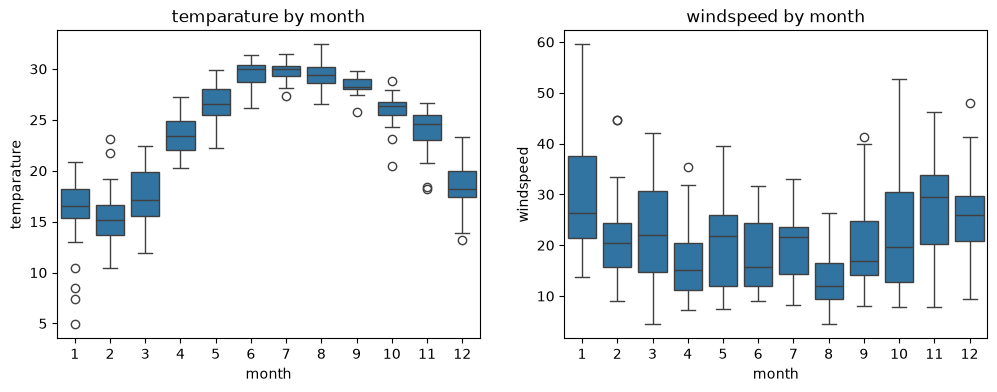

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
import seaborn as sns
for ax,col in zip(axes,['temparature','windspeed']):
    sns.boxplot(data=df,x='month',y=col,ax=ax)
    ax.set_title(f"{col} by month")

In [16]:
# right test picker 
def relate(cat_col,num_col,data=df):
    d=data[[cat_col,num_col]].dropna()
    samples=[g[num_col].values for _,g in d.groupby(cat_col)]
    k=len(samples)
    res={
        "categorical": cat_col,
        "numerical":num_col,
        "groups":k
    }
    if k==2:
        res['parametric_test'],res['parametric_p']= 'Welch t-test',stats.ttest_ind(*samples,equal_var=False).pvalue
        res['nonparametric_test'],res['nonparametric_p']= 'Mann-Whitney U',stats.mannwhitneyu(*samples).pvalue
    else:
        res['parametric_test'],res['parametric_p']= 'One-way ANOVA',stats.f_oneway(*samples,equal_var=False).pvalue
        res['nonparametric_test'],res['nonparametric_p']= 'Kruskal_Wallis',stats.kruskal(*samples).pvalue  
    res['eta']=correlation_ratio(d[cat_col],d[num_col])
    # eta works for multiple groups 
    return res
pd.DataFrame([relate('rainfall','humidity'),relate('month','humidity')])



,categorical,numerical,groups,parametric_test,parametric_p,nonparametric_test,nonparametric_p,eta
0,rainfall,humidity,2,Welch t-test,0.0000,Mann-Whitney U,0.0000,0.4891
1,month,humidity,12,One-way ANOVA,0.0000,Kruskal_Wallis,0.0000,0.3937
